In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [91]:
pip install kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [23]:
import kagglehub

# Download selected version
path = kagglehub.dataset_download("chaitu20/ipl-dataset2008-2025/versions/1")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1


In [24]:
import os

# Store the path returned by kagglehub
dataset_path = r"C:\Users\sohag\.cache\kagglehub\datasets\chaitu20\ipl-dataset2008-2025\versions\1"

# List all files inside that folder
print(os.listdir(dataset_path))

['IPL.csv']


In [25]:
# Combine the folder path with the exact file name
csv_file_path = os.path.join(dataset_path,"IPL.csv" )  # Replace with the actual file name printed above

# Load the data
df = pd.read_csv(csv_file_path)

# Preview the first 5 rows
df.head()

C:\Users\sohag\AppData\Local\Temp\ipykernel_15760\1186300335.py:5: DtypeWarning: Columns (28: review_batter, 29: team_reviewed, 30: review_decision, 31: umpire, 43: season, 46: superover_winner, 47: result_type, 48: method, 51: event_match_no) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_file_path)


,Unnamed: 0,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,...,team_runs,team_balls,team_wicket,new_batter,batter_runs,batter_balls,bowler_wicket,batting_partners,next_batter,striker_out
0,131970,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,...,1,1,0,NaN,0,1,0,"('BB McCullum', 'SC Ganguly')",NaN,False
1,131971,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,...,1,2,0,NaN,0,1,0,"('BB McCullum', 'SC Ganguly')",NaN,False
2,131972,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,...,2,2,0,NaN,0,1,0,"('BB McCullum', 'SC Ganguly')",NaN,False
3,131973,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,...,2,3,0,NaN,0,2,0,"('BB McCullum', 'SC Ganguly')",NaN,False
4,131974,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,...,2,4,0,NaN,0,3,0,"('BB McCullum', 'SC Ganguly')",NaN,False


In [26]:
print(df.columns.tolist())

['Unnamed: 0', 'match_id', 'date', 'match_type', 'event_name', 'innings', 'batting_team', 'bowling_team', 'over', 'ball', 'ball_no', 'batter', 'bat_pos', 'runs_batter', 'balls_faced', 'bowler', 'valid_ball', 'runs_extras', 'runs_total', 'runs_bowler', 'runs_not_boundary', 'extra_type', 'non_striker', 'non_striker_pos', 'wicket_kind', 'player_out', 'fielders', 'runs_target', 'review_batter', 'team_reviewed', 'review_decision', 'umpire', 'umpires_call', 'player_of_match', 'match_won_by', 'win_outcome', 'toss_winner', 'toss_decision', 'venue', 'city', 'day', 'month', 'year', 'season', 'gender', 'team_type', 'superover_winner', 'result_type', 'method', 'balls_per_over', 'overs', 'event_match_no', 'stage', 'match_number', 'team_runs', 'team_balls', 'team_wicket', 'new_batter', 'batter_runs', 'batter_balls', 'bowler_wicket', 'batting_partners', 'next_batter', 'striker_out']


In [27]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 278205 entries, 0 to 278204
Data columns (total 64 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         278205 non-null  int64  
 1   match_id           278205 non-null  int64  
 2   date               278205 non-null  str    
 3   match_type         278205 non-null  str    
 4   event_name         278205 non-null  str    
 5   innings            278205 non-null  int64  
 6   batting_team       278205 non-null  str    
 7   bowling_team       278205 non-null  str    
 8   over               278205 non-null  int64  
 9   ball               278205 non-null  int64  
 10  ball_no            278205 non-null  float64
 11  batter             278205 non-null  str    
 12  bat_pos            278205 non-null  int64  
 13  runs_batter        278205 non-null  int64  
 14  balls_faced        278205 non-null  int64  
 15  bowler             278205 non-null  str    
 16  valid_ball   

In [28]:
# Check dataset shape
print("Dataset Shape:", df.shape)

Dataset Shape: (278205, 64)


In [29]:
# Extract unique matches
matches_df = df.drop_duplicates(subset=['match_id']).copy()

print(f"Total Unique Matches: {len(matches_df)}")

Total Unique Matches: 1169


In [30]:
# Mapping dictionary for team name updates
team_mapping = {
    'Rising Pune Supergiant': 'Rising Pune Supergiants',
    'Delhi Daredevils': 'Delhi Capitals',
    'Kings XI Punjab': 'Punjab Kings',
    'Deccan Chargers': 'Sunrisers Hyderabad',
    'Royal Challengers Bengaluru': 'Royal Challengers Bangalore'
}

# Replace team names across all relevant columns
team_cols = ['batting_team', 'bowling_team', 'toss_winner', 'match_won_by']
for col in team_cols:
    if col in matches_df.columns:
        matches_df[col] = matches_df[col].replace(team_mapping)

In [31]:
# 1. Fill missing winners (e.g., abandoned or rained out matches)
matches_df['match_won_by'] = matches_df['match_won_by'].fillna('No Result')

# 2. Fill missing outcome details
if 'win_outcome' in matches_df.columns:
    matches_df['win_outcome'] = matches_df['win_outcome'].fillna('No Result')

# 3. Fill missing player of the match
if 'player_of_match' in matches_df.columns:
    matches_df['player_of_match'] = matches_df['player_of_match'].fillna('None')

# 4. Fill missing city based on venue
matches_df['city'] = matches_df['city'].fillna('Unknown')

In [32]:
# Convert date to datetime format
matches_df['date'] = pd.to_datetime(matches_df['date'])

# Verify season is formatted cleanly
matches_df['season'] = matches_df['season'].astype(str)

In [40]:
# Feature: Did the toss winner win the match?
matches_df['toss_match_winner'] = (matches_df['toss_winner'] == matches_df['match_won_by']).astype(int)

In [76]:
for v in sorted(matches_df['venue'].unique()):
    print(v)

Arun Jaitley Stadium
Arun Jaitley Stadium, Delhi
Barabati Stadium
Barsapara Cricket Stadium, Guwahati
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium, Lucknow
Brabourne Stadium
Brabourne Stadium, Mumbai
Buffalo Park
De Beers Diamond Oval
Dr DY Patil Sports Academy
Dr DY Patil Sports Academy, Mumbai
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium
Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium, Visakhapatnam
Dubai International Cricket Stadium
Eden Gardens
Eden Gardens, Kolkata
Feroz Shah Kotla
Green Park
Himachal Pradesh Cricket Association Stadium
Himachal Pradesh Cricket Association Stadium, Dharamsala
Holkar Cricket Stadium
JSCA International Stadium Complex
Kingsmead
M Chinnaswamy Stadium
M Chinnaswamy Stadium, Bengaluru
M.Chinnaswamy Stadium
MA Chidambaram Stadium
MA Chidambaram Stadium, Chepauk
MA Chidambaram Stadium, Chepauk, Chennai
Maharaja Yadavindra Singh International Cricket Stadium, Mullanpur
Maharaja Yadavindra Singh International Cricket Stadium, Ne

In [77]:
# 1. drop the ", City" suffix (handles "X", "X, City" and "X, Area, City" alike)
matches_df['venue'] = matches_df['venue'].str.split(',').str[0].str.strip()

# 2. merge renamed / respelled grounds
venue_mapping = {
    'Feroz Shah Kotla':                    'Arun Jaitley Stadium',        # renamed
    'M.Chinnaswamy Stadium':               'M Chinnaswamy Stadium',       # spacing
    'Punjab Cricket Association Stadium':  'Punjab Cricket Association IS Bindra Stadium',  # old name
    'Sardar Patel Stadium':                'Narendra Modi Stadium',       # Motera, renamed
    'Zayed Cricket Stadium':               'Sheikh Zayed Stadium',        # Abu Dhabi
    'Subrata Roy Sahara Stadium':          'Maharashtra Cricket Association Stadium',  # Pune, renamed
}
matches_df['venue'] = matches_df['venue'].replace(venue_mapping)

print(matches_df['venue'].nunique())
print(sorted(matches_df['venue'].unique()))

36
['Arun Jaitley Stadium', 'Barabati Stadium', 'Barsapara Cricket Stadium', 'Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium', 'Brabourne Stadium', 'Buffalo Park', 'De Beers Diamond Oval', 'Dr DY Patil Sports Academy', 'Dr. Y.S. Rajasekhara Reddy ACA-VDCA Cricket Stadium', 'Dubai International Cricket Stadium', 'Eden Gardens', 'Green Park', 'Himachal Pradesh Cricket Association Stadium', 'Holkar Cricket Stadium', 'JSCA International Stadium Complex', 'Kingsmead', 'M Chinnaswamy Stadium', 'MA Chidambaram Stadium', 'Maharaja Yadavindra Singh International Cricket Stadium', 'Maharashtra Cricket Association Stadium', 'Narendra Modi Stadium', 'Nehru Stadium', 'New Wanderers Stadium', 'Newlands', 'OUTsurance Oval', 'Punjab Cricket Association IS Bindra Stadium', 'Rajiv Gandhi International Stadium', 'Saurashtra Cricket Association Stadium', 'Sawai Mansingh Stadium', 'Shaheed Veer Narayan Singh International Stadium', 'Sharjah Cricket Stadium', 'Sheikh Zayed Stadium', "St George

In [87]:
home_grounds = {
    'Chennai Super Kings':          ['MA Chidambaram'],
    'Mumbai Indians':               ['Wankhede'],
    'Kolkata Knight Riders':        ['Eden Gardens'],
    'Royal Challengers Bangalore':  ['M Chinnaswamy'],
    'Delhi Capitals':               ['Arun Jaitley'],
    'Punjab Kings':                 ['Punjab Cricket Association', 'Maharaja Yadavindra'],
    'Rajasthan Royals':             ['Sawai Mansingh'],
    'Sunrisers Hyderabad':          ['Rajiv Gandhi'],
}

home_stats = []
for team, prefixes in home_grounds.items():
    played = matches_df[(matches_df['batting_team'] == team) | (matches_df['bowling_team'] == team)]
    is_home = played['venue'].str.startswith(tuple(prefixes))
    home = played[is_home]
    away = played[~is_home]

    home_win_pct = (home['match_won_by'] == team).mean() * 100 if len(home) else 0
    away_win_pct = (away['match_won_by'] == team).mean() * 100 if len(away) else 0

    home_stats.append({
        'Team': team,
        'Home Win %': round(home_win_pct, 2),
        'Away/Neutral Win %': round(away_win_pct, 2),
        'Home Matches': len(home),
    })

home_df = pd.DataFrame(home_stats)
print(home_df.to_string(index=False))

                       Team  Home Win %  Away/Neutral Win %  Home Matches
        Chennai Super Kings       66.23               52.00            77
             Mumbai Indians       60.87               51.35            92
      Kolkata Knight Riders       56.84               47.93            95
Royal Challengers Bangalore       47.37               49.71            95
             Delhi Capitals       41.38               45.56            87
               Punjab Kings       47.89               44.04            71
           Rajasthan Royals       61.29               43.93            62
        Sunrisers Hyderabad       49.38               43.16            81


In [88]:
# Inspect cleaned match dataframe summary
print("Cleaned Match Table Shape:", matches_df.shape)
matches_df[['match_id', 'date', 'season', 'toss_winner', 'toss_decision', 'match_won_by', 'toss_match_winner']].head()

Cleaned Match Table Shape: (1169, 66)


,match_id,date,season,toss_winner,toss_decision,match_won_by,toss_match_winner
0,335982,2008-04-18,2007/08,Royal Challengers Bangalore,field,Kolkata Knight Riders,0
1,335983,2008-04-19,2007/08,Chennai Super Kings,bat,Chennai Super Kings,1
2,335984,2008-04-19,2007/08,Rajasthan Royals,bat,Delhi Capitals,0
3,335985,2008-04-20,2007/08,Mumbai Indians,bat,Royal Challengers Bangalore,0
4,335986,2008-04-20,2007/08,Sunrisers Hyderabad,bat,Kolkata Knight Riders,0


In [89]:
import os

# Create the data folder if it doesn't exist yet
os.makedirs('data', exist_ok=True)

# Save the cleaned dataframe
matches_df.to_csv('data/cleaned_matches.csv', index=False)
print("Successfully saved to IDC 409/data/cleaned_matches.csv!")

Successfully saved to IDC 409/data/cleaned_matches.csv!


In [90]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# Load pre-cleaned dataset from yesterday
matches_df = pd.read_csv('data/cleaned_matches.csv')
matches_df.head()

,Unnamed: 0,match_id,date,match_type,event_name,innings,batting_team,bowling_team,over,ball,...,team_wicket,new_batter,batter_runs,batter_balls,bowler_wicket,batting_partners,next_batter,striker_out,toss_is_match_winner,toss_match_winner
0,131970,335982,2008-04-18,T20,Indian Premier League,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,...,0,NaN,0,1,0,"('BB McCullum', 'SC Ganguly')",NaN,False,False,0
1,132195,335983,2008-04-19,T20,Indian Premier League,1,Chennai Super Kings,Punjab Kings,0,1,...,0,NaN,0,1,0,"('ML Hayden', 'PA Patel')",NaN,False,True,1
2,132443,335984,2008-04-19,T20,Indian Premier League,1,Rajasthan Royals,Delhi Capitals,0,1,...,0,NaN,0,1,0,"('T Kohli', 'YK Pathan')",NaN,False,False,0
3,132662,335985,2008-04-20,T20,Indian Premier League,1,Mumbai Indians,Royal Challengers Bangalore,0,1,...,0,NaN,0,1,0,"('L Ronchi', 'ST Jayasuriya')",NaN,False,False,0
4,132908,335986,2008-04-20,T20,Indian Premier League,1,Sunrisers Hyderabad,Kolkata Knight Riders,0,1,...,0,NaN,1,1,0,"('AC Gilchrist', 'Y Venugopal Rao')",NaN,False,False,0


In [91]:
#1. DOES WINNING THE TOSS GIVE A MATCH ADVANTAGE?

Percentage of matches won by the toss winner: 50.56%


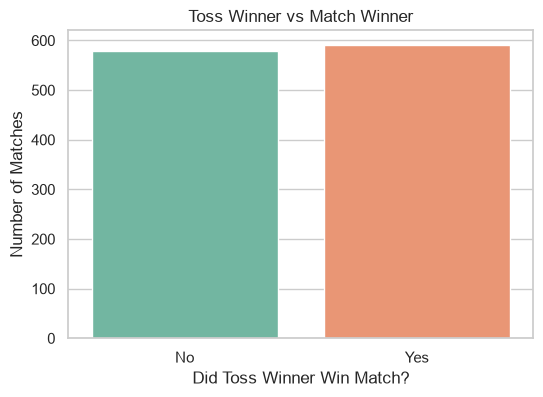

In [92]:
# Calculate toss advantage
matches_df['toss_is_match_winner'] = (matches_df['toss_winner'] == matches_df['match_won_by'])
toss_win_pct = matches_df['toss_is_match_winner'].value_counts(normalize=True) * 100

print(f"Percentage of matches won by the toss winner: {toss_win_pct.get(True, 0):.2f}%")

# Visualization
plt.figure(figsize=(6, 4))
sns.countplot(data=matches_df, x='toss_is_match_winner',hue= 'toss_is_match_winner', palette='Set2', legend=False)
plt.title('Toss Winner vs Match Winner')
plt.xlabel('Did Toss Winner Win Match?')
plt.ylabel('Number of Matches')
plt.xticks([0, 1], ['No', 'Yes'])
plt.show()

In [93]:
#2. TOSS DECISION TRENDS (BATTING FIRST VS CHASING)

Toss Decision Breakdown:
toss_decision
field    764
bat      405
Name: count, dtype: int64

Win Rate based on Decision Choice:
toss_decision
bat      45.185185
field    53.403141
Name: toss_is_match_winner, dtype: float64


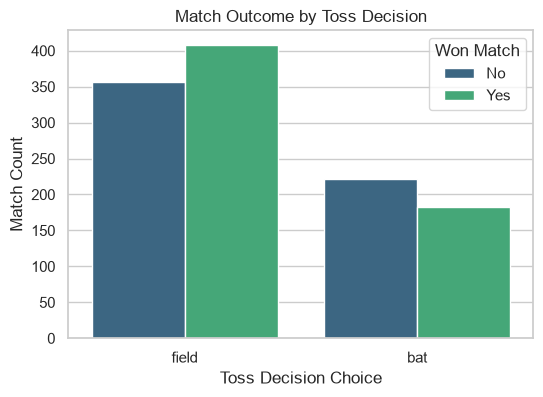

In [94]:
# Overall toss decision breakdown
toss_decisions = matches_df['toss_decision'].value_counts()
print("Toss Decision Breakdown:")
print(toss_decisions)

# Win rate by toss decision
decision_win_rate = matches_df.groupby('toss_decision')['toss_is_match_winner'].mean() * 100
print("\nWin Rate based on Decision Choice:")
print(decision_win_rate)

# Visualization
plt.figure(figsize=(6, 4))
sns.countplot(data=matches_df, x='toss_decision', hue='toss_is_match_winner', palette='viridis')
plt.title('Match Outcome by Toss Decision')
plt.xlabel('Toss Decision Choice')
plt.ylabel('Match Count')
plt.legend(title='Won Match', labels=['No', 'Yes'])
plt.show()

In [95]:
#3. MATCH OUTCOMES (BATTING FIRST VS CHASING)

Matches Won Batting First: 531
Matches Won Chasing: 615
No Result / Abandoned / Ties: 23


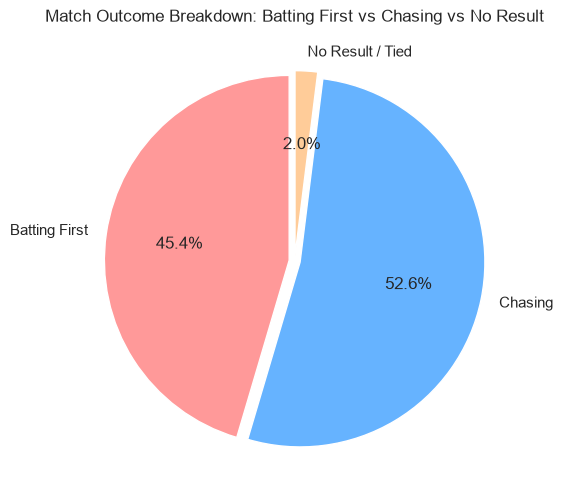

In [96]:
# Ensure we analyze unique match records
unique_matches = matches_df.drop_duplicates(subset=['match_id']).copy()

# Count wins using .str.contains() to match strings like '140 runs' or '6 wickets'
bat_first_wins = unique_matches['win_outcome'].astype(str).str.contains('runs', case=False, na=False).sum()
chasing_wins = unique_matches['win_outcome'].astype(str).str.contains('wicket', case=False, na=False).sum()
no_result = len(unique_matches) - (bat_first_wins + chasing_wins)

print(f"Matches Won Batting First: {bat_first_wins}")
print(f"Matches Won Chasing: {chasing_wins}")
print(f"No Result / Abandoned / Ties: {no_result}")

# Outcome categories and visuals
labels = ['Batting First', 'Chasing', 'No Result / Tied']
values = [bat_first_wins, chasing_wins, no_result]
colors = ['#ff9999', '#66b3ff', '#ffcc99']

# Filter out categories with 0 occurrences so matplotlib doesn't throw wedge errors
plot_values = [val for val in values if val > 0]
plot_labels = [label for label, val in zip(labels, values) if val > 0]
plot_colors = [colors[i] for i, val in enumerate(values) if val > 0]
explode = [0.03] * len(plot_values)

# Render Pie / Donut Chart
plt.figure(figsize=(6, 6))
plt.pie(
    plot_values, 
    labels=plot_labels, 
    autopct='%1.1f%%', 
    colors=plot_colors, 
    startangle=90,
    explode=explode
)
plt.title('Match Outcome Breakdown: Batting First vs Chasing vs No Result')
plt.show()

In [97]:
#4. TOP PERFORMING TEAMS (TOAL MATCHES WON ACROSS SEASONS)

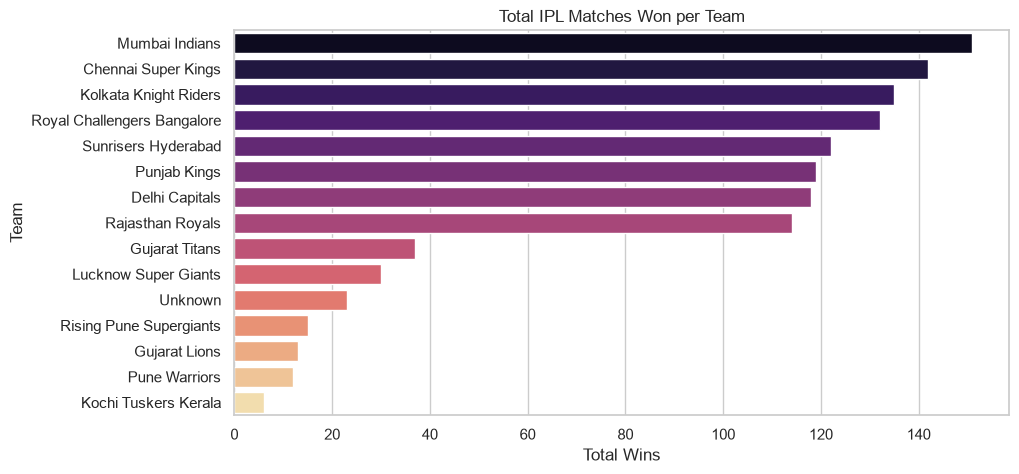

In [98]:
top_teams = matches_df[matches_df['match_won_by'] != 'No Result']['match_won_by'].value_counts()

plt.figure(figsize=(10, 5))
sns.barplot(x=top_teams.values, y=top_teams.index,hue= top_teams.index,palette='magma',legend=False)
plt.title('Total IPL Matches Won per Team')
plt.xlabel('Total Wins')
plt.ylabel('Team')
plt.show()

In [99]:
matches_df[matches_df['match_won_by'] == 'Unknown'][['match_id','date','batting_team','bowling_team','win_outcome']]

,match_id,date,batting_team,bowling_team,win_outcome
66,392190,2009-04-23,Rajasthan Royals,Kolkata Knight Riders,No Result
130,419121,2010-03-21,Punjab Kings,Chennai Super Kings,No Result
241,501265,2011-05-21,Delhi Capitals,Pune Warriors,No Result
328,598004,2013-04-07,Royal Challengers Bangalore,Sunrisers Hyderabad,No Result
342,598017,2013-04-16,Delhi Capitals,Royal Challengers Bangalore,No Result
416,729315,2014-04-29,Rajasthan Royals,Kolkata Knight Riders,No Result
475,829741,2015-04-21,Rajasthan Royals,Punjab Kings,No Result
485,829763,2015-04-29,Royal Challengers Bangalore,Rajasthan Royals,No Result
511,829813,2015-05-17,Delhi Capitals,Royal Challengers Bangalore,No Result
610,1082625,2017-04-29,Gujarat Lions,Mumbai Indians,No Result


In [100]:
#5. VENUE IMPACT:TOP STADIUMS BY MATCH VOLUME AND WIN TRENDS

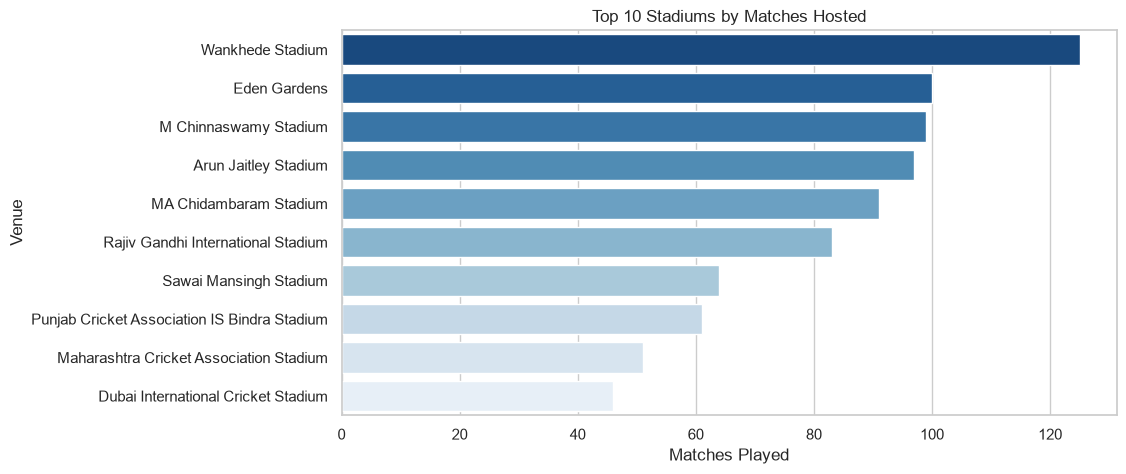


Most Dominant Team at Top Venues:
 - Wankhede Stadium: Mumbai Indians (56 wins)
 - Eden Gardens: Kolkata Knight Riders (54 wins)
 - M Chinnaswamy Stadium: Royal Challengers Bangalore (45 wins)
 - Arun Jaitley Stadium: Delhi Capitals (36 wins)
 - MA Chidambaram Stadium: Chennai Super Kings (51 wins)


In [101]:
# 1. Top venues by volume
top_venues = matches_df['venue'].value_counts().head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_venues.values, y=top_venues.index, hue=top_venues.index, palette='Blues_r', legend=False)
plt.title('Top 10 Stadiums by Matches Hosted')
plt.xlabel('Matches Played')
plt.ylabel('Venue')
plt.show()

# 2. Most successful team at top venues
print("\nMost Dominant Team at Top Venues:")
venue_wins = matches_df.groupby(['venue', 'match_won_by']).size().unstack(fill_value=0)
for venue in top_venues.index[:5]:
    top_team = venue_wins.loc[venue].idxmax()
    wins = venue_wins.loc[venue].max()
    print(f" - {venue}: {top_team} ({int(wins)} wins)")

In [102]:
#6. VENUE EFFECT: DOES THE HOME TEAMS GET ADVANTAGES PLAYING IN THEIR HOME VENUES?

                       Team  Home Win %  Away/Neutral Win %  Home Matches
        Chennai Super Kings       63.64               51.63            99
             Mumbai Indians       60.87               51.35            92
      Kolkata Knight Riders       56.84               47.93            95
Royal Challengers Bangalore       49.60               40.91           248
             Delhi Capitals       41.38               45.56            87
               Punjab Kings       50.82               43.35            61
           Rajasthan Royals       61.29               43.93            62
        Sunrisers Hyderabad       49.38               43.16            81


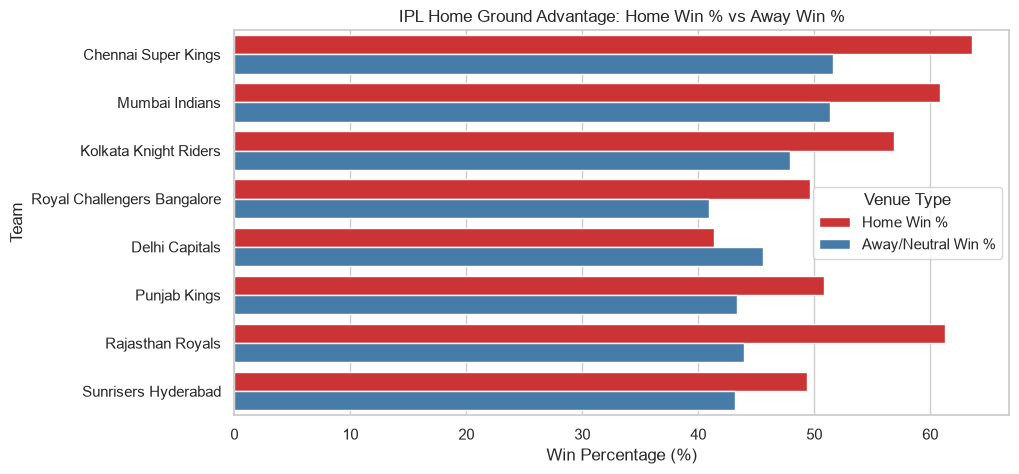

In [104]:
# Map primary IPL teams to their official home grounds
home_grounds = {
    'Chennai Super Kings': 'MA Chidambaram Stadium',
    'Mumbai Indians': 'Wankhede Stadium',
    'Kolkata Knight Riders': 'Eden Gardens',
    'Royal Challengers Bangalore': 'M Chinnaswamy Stadium',
    'Delhi Capitals': 'Arun Jaitley Stadium',
    'Punjab Kings': 'Punjab Cricket Association IS Bindra Stadium',
    'Rajasthan Royals': 'Sawai Mansingh Stadium',
    'Sunrisers Hyderabad': 'Rajiv Gandhi International Stadium'
}

home_stats = []

for team, venue in home_grounds.items():
    # Matches involving the team at their home venue
    home_matches = matches_df[
        ((matches_df['batting_team'] == team) | (matches_df['bowling_team'] == team)) & 
        (matches_df['venue'].str.contains(venue.split()[0], case=False, na=False))
    ].drop_duplicates(subset=['match_id'])
    
    # Matches involving the team away/neutral
    away_matches = matches_df[
        ((matches_df['batting_team'] == team) | (matches_df['bowling_team'] == team)) & 
        (~matches_df['venue'].str.contains(venue.split()[0], case=False, na=False))
    ].drop_duplicates(subset=['match_id'])
    
    total_home = len(home_matches)
    home_wins = (home_matches['match_won_by'] == team).sum()
    home_win_pct = (home_wins / total_home * 100) if total_home > 0 else 0
    
    total_away = len(away_matches)
    away_wins = (away_matches['match_won_by'] == team).sum()
    away_win_pct = (away_wins / total_away * 100) if total_away > 0 else 0
    
    home_stats.append({
        'Team': team,
        'Home Win %': round(home_win_pct, 2),
        'Away/Neutral Win %': round(away_win_pct, 2),
        'Home Matches': total_home
    })

import pandas as pd
home_df = pd.DataFrame(home_stats)
print(home_df.to_string(index=False))

#Visulaize
plt.figure(figsize=(10, 5))
home_df_melted = home_df.melt(id_vars=['Team', 'Home Matches'], value_vars=['Home Win %', 'Away/Neutral Win %'], var_name='Location', value_name='Win Percentage')
sns.barplot(data=home_df_melted, x='Win Percentage', y='Team', hue='Location', palette='Set1')
plt.title('IPL Home Ground Advantage: Home Win % vs Away Win %')
plt.xlabel('Win Percentage (%)')
plt.ylabel('Team')
plt.legend(title='Venue Type')
plt.show()

In [105]:
#7.PLAYER OF MATCH PATTERNS: MOST FREQUENT AWARD WINNERS

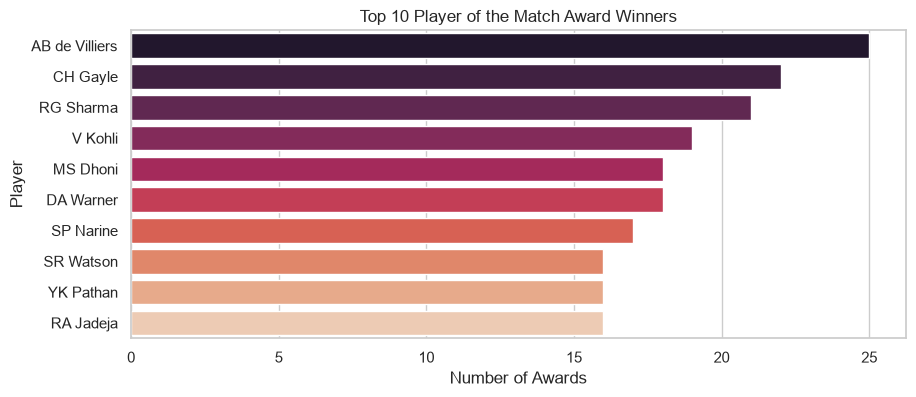

In [106]:
top_mom = matches_df[matches_df['player_of_match'] != 'None']['player_of_match'].value_counts().head(10)

plt.figure(figsize=(10, 4))
sns.barplot(x=top_mom.values, y=top_mom.index,hue= top_mom.index, palette='rocket', legend=False)
plt.title('Top 10 Player of the Match Award Winners')
plt.xlabel('Number of Awards')
plt.ylabel('Player')
plt.show()

In [107]:
#8. MAN OF SERIES PATTERN (MOST MVP AWARDS PER SEASON)

Top Player of the Match Award Winner Per Season:
 season player_of_match  awards_count
2007/08        SE Marsh             5
   2009       YK Pathan             3
2009/10    SR Tendulkar             4
   2011        CH Gayle             6
   2012        CH Gayle             5
   2013      MEK Hussey             5
   2014      GJ Maxwell             4
   2015       DA Warner             4
   2016         V Kohli             5
   2017       BA Stokes             3
   2018     Rashid Khan             4
   2019      AD Russell             4
2020/21  AB de Villiers             3
   2021      RD Gaikwad             4
   2022   Kuldeep Yadav             4
   2023    Shubman Gill             4
   2024 Abhishek Sharma             3
   2025       KH Pandya             3


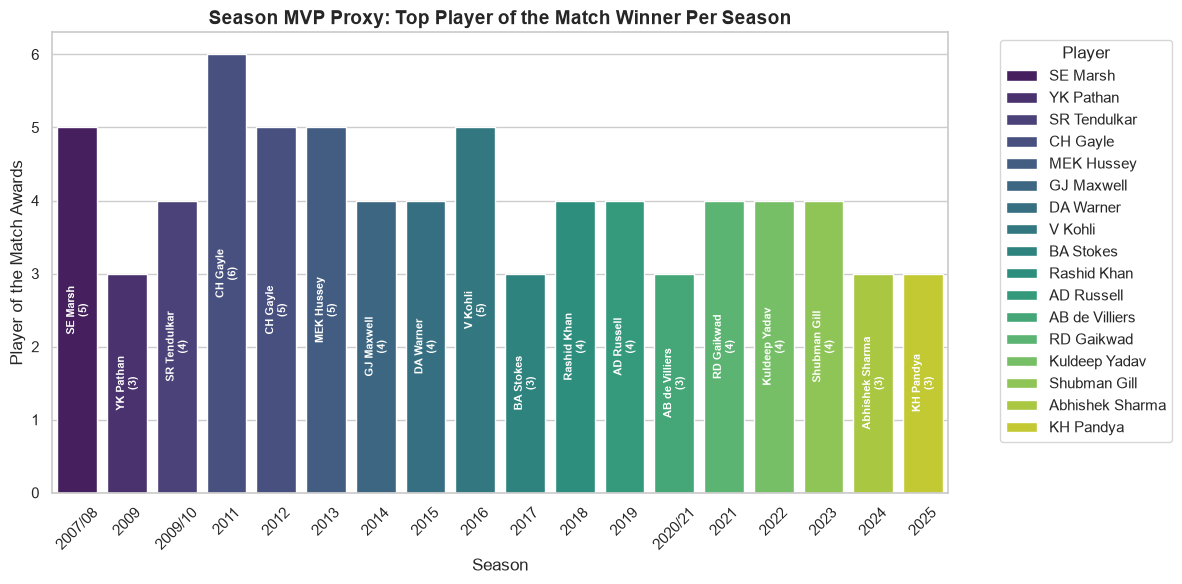

In [108]:
# Group by season and player_of_match to count awards per season
season_mom = matches_df[matches_df['player_of_match'] != 'None'].groupby(['season', 'player_of_match']).size().reset_index(name='awards_count')

# Get the top award winner(s) for each season
season_mvp = season_mom.sort_values(['season', 'awards_count'], ascending=[True, False]).groupby('season').head(1).reset_index(drop=True)

# Format season labels nicely for the x-axis
season_mvp['season_label'] = season_mvp['season'].astype(str)
season_mvp['player_season'] = season_mvp['player_of_match'] + ' (' + season_mvp['season_label'] + ')'

print("Top Player of the Match Award Winner Per Season:")
print(season_mvp[['season', 'player_of_match', 'awards_count']].to_string(index=False))

# Visualization: Bar plot of Most Player of the Match awards by Season
plt.figure(figsize=(12, 6))
barplot = sns.barplot(
    data=season_mvp, 
    x='season_label', 
    y='awards_count', 
    hue='player_of_match', 
    dodge=False,
    palette='viridis'
)

plt.title('Season MVP Proxy: Top Player of the Match Winner Per Season', fontsize=14, fontweight='bold')
plt.xlabel('Season', fontsize=12)
plt.ylabel('Player of the Match Awards', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Player', bbox_to_anchor=(1.05, 1), loc='upper left')

# Annotate each bar with the player name and award count
for p, name in zip(barplot.patches, season_mvp['player_of_match']):
    if p.get_height() > 0:
        barplot.annotate(
            f'{name}\n({int(p.get_height())})',
            (p.get_x() + p.get_width() / 2., p.get_height() / 2),
            ha='center', va='center',
            fontsize=8, color='white', fontweight='bold',
            rotation=90
        )

plt.tight_layout()
plt.show()

In [109]:
#9. SEASON TRENDS: TOTAL MATCHES PLAYED PER SEASON

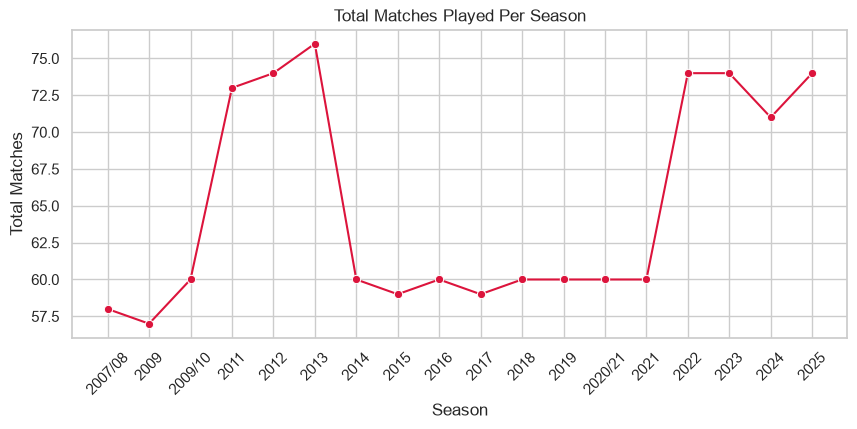

In [110]:
season_matches = matches_df['season'].value_counts().sort_index()

plt.figure(figsize=(10, 4))
sns.lineplot(x=season_matches.index.astype(str), y=season_matches.values, marker='o', color='crimson')
plt.title('Total Matches Played Per Season')
plt.xlabel('Season')
plt.ylabel('Total Matches')
plt.xticks(rotation=45)
plt.show()

In [111]:
#10. WEATHER INTERRUPTIONS- RAIN

In [112]:
# Check for DLS method or abandoned matches
if 'method' in matches_df.columns:
    weather_affected = matches_df['method'].value_counts()
    print("Matches Affected by DLS/Weather Method:")
    print(weather_affected)

no_result_count = (matches_df['match_won_by'] == 'No Result').sum()
print(f"Total Abandoned / No Result Matches: {no_result_count}")

Matches Affected by DLS/Weather Method:
method
D/L    22
Name: count, dtype: int64
Total Abandoned / No Result Matches: 0


Total DLS/Rain Affected Matches: 22
DLS Matches Won by Chasing Team: 10 (45.5%)
DLS Matches Won by Batting First Team: 12 (54.5%)

--- Match Outcome by Environmental / Contextual Factors ---


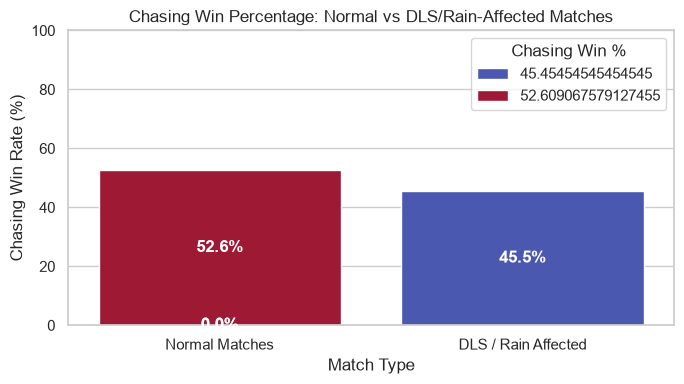

In [113]:
unique_matches = matches_df.drop_duplicates(subset=['match_id']).copy()

# DLS / Rain Impact Analysis
dls_matches = unique_matches[unique_matches['method'].astype(str).str.contains('D/L|DLS', case=False, na=False)]

print(f"Total DLS/Rain Affected Matches: {len(dls_matches)}")

if len(dls_matches) > 0:
    # Determine if chasing team won DLS matches
    dls_chase_wins = dls_matches['win_outcome'].astype(str).str.contains('wicket', case=False, na=False).sum()
    dls_bat_first_wins = dls_matches['win_outcome'].astype(str).str.contains('runs', case=False, na=False).sum()
    
    print(f"DLS Matches Won by Chasing Team: {dls_chase_wins} ({dls_chase_wins/len(dls_matches)*100:.1f}%)")
    print(f"DLS Matches Won by Batting First Team: {dls_bat_first_wins} ({dls_bat_first_wins/len(dls_matches)*100:.1f}%)")

# Match Type / Time of Day Analysis (Day vs Night / Day-Night)
# Check if dataset has match type or lighting conditions
if 'match_type' in unique_matches.columns or 'event_name' in unique_matches.columns:
    print("\n--- Match Outcome by Environmental / Contextual Factors ---")
    
# Plotting DLS Advantage vs Normal Matches
fig, ax = plt.subplots(figsize=(7, 4))
dls_summary = pd.DataFrame({
    'Match Type': ['Normal Matches', 'DLS / Rain Affected'],
    'Chasing Win %': [
        (unique_matches['win_outcome'].astype(str).str.contains('wicket', case=False, na=False).sum() / len(unique_matches)) * 100,
        (dls_chase_wins / len(dls_matches) * 100) if len(dls_matches) > 0 else 0
    ]
})

sns.barplot(data=dls_summary, x='Match Type', y='Chasing Win %',hue= 'Chasing Win %', palette='coolwarm', ax=ax)
ax.set_title('Chasing Win Percentage: Normal vs DLS/Rain-Affected Matches')
ax.set_ylabel('Chasing Win Rate (%)')
ax.set_ylim(0, 100)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

In [114]:
#11. WEATHER INTERUPPTIONS: DEW EFFECT


% of Times Captains Choose to Field First (Dew Strategy): 65.36%
Win % when Captains Choose to Field First: 53.40%


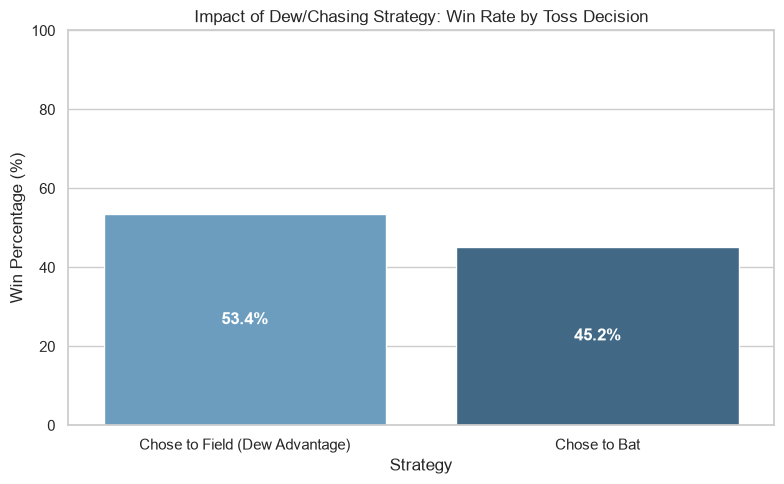

In [115]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure unique match records
unique_matches = matches_df.drop_duplicates(subset=['match_id']).copy()

# Classify Day vs Night matches (if 'match_type' or time information is available)
# In IPL datasets without exact time, Night matches are often identified via match order or specific columns.
# If venue/lighting info is present, we compare Chasing Win % in Day vs Night matches.

#Analyzing 2nd Innings Batting Advantage (Dew Proxy)
# Merge ball-by-ball data with match outcomes to check 2nd innings run rate and boundaries
if 'inning' in matches_df.columns and 'total_runs' in matches_df.columns:
    innings_summary = matches_df.groupby(['match_id', 'inning'])['total_runs'].sum().reset_index()
    
    inn1 = innings_summary[innings_summary['inning'] == 1].rename(columns={'total_runs': 'inn1_runs'})
    inn2 = innings_summary[innings_summary['inning'] == 2].rename(columns={'total_runs': 'inn2_runs'})
    
    scoring_comparison = pd.merge(inn1, inn2, on='match_id')
    
    print("Average 1st Innings Score:", round(scoring_comparison['inn1_runs'].mean(), 2))
    print("Average 2nd Innings Score:", round(scoring_comparison['inn2_runs'].mean(), 2))

#Toss Decision Trends (Toss winner choosing to Field First due to Dew)
toss_field_pct = (unique_matches['toss_decision'] == 'field').mean() * 100
toss_field_win_pct = (
    (unique_matches['toss_winner'] == unique_matches['match_won_by']) & 
    (unique_matches['toss_decision'] == 'field')
).sum() / (unique_matches['toss_decision'] == 'field').sum() * 100

print(f"\n% of Times Captains Choose to Field First (Dew Strategy): {toss_field_pct:.2f}%")
print(f"Win % when Captains Choose to Field First: {toss_field_win_pct:.2f}%")

# Visualization: Chasing Success Rate as a Proxy for Dew Factor
fig, ax = plt.subplots(figsize=(8, 5))
toss_outcome = pd.DataFrame({
    'Strategy': ['Chose to Field (Dew Advantage)', 'Chose to Bat'],
    'Win %': [
        toss_field_win_pct,
        ((unique_matches['toss_winner'] == unique_matches['match_won_by']) & 
         (unique_matches['toss_decision'] == 'bat')).sum() / (unique_matches['toss_decision'] == 'bat').sum() * 100
    ]
})

sns.barplot(data=toss_outcome, x='Strategy', y='Win %',hue= 'Strategy', palette='Blues_d', ax=ax)
ax.set_title('Impact of Dew/Chasing Strategy: Win Rate by Toss Decision')
ax.set_ylabel('Win Percentage (%)')
ax.set_ylim(0, 100)

for p in ax.patches:
    ax.annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

In [116]:
#12. SCORING RANGE AND MATCH TOTAL DISTRIBUTIONS

Total matches processed: 1169
1st Innings Score Summary:
count    1169.000000
mean      167.021386
std        32.948414
min        56.000000
25%       147.000000
50%       167.000000
75%       188.000000
max       287.000000
Name: runs_total, dtype: float64


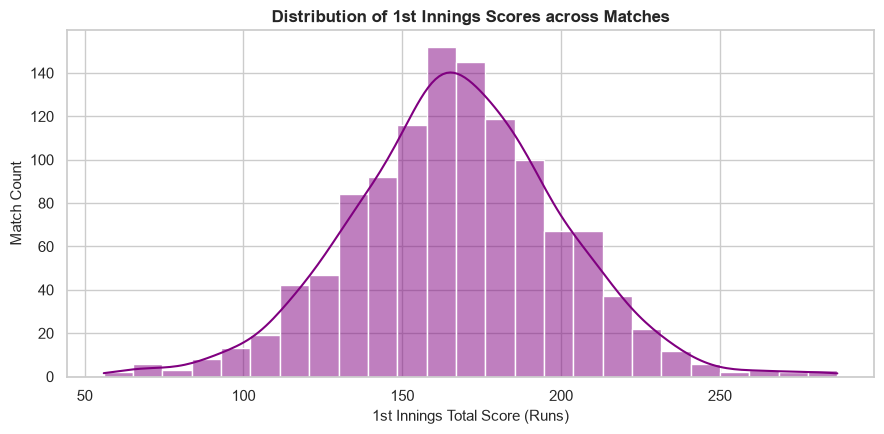

In [118]:
# Construct the full path to IPL.csv
file_path = os.path.join(dataset_path, 'IPL.csv')

# Load the ball-by-ball dataset
df_balls = pd.read_csv(file_path, low_memory=False)

# Filter for 1st innings deliveries
inn1_balls = df_balls[df_balls['innings'] == 1]

# Aggregate total 1st innings runs for each match
inn1_scores = inn1_balls.groupby('match_id')['runs_total'].sum()

# Filter out incomplete/shortened matches if needed (e.g., scores > 50)
inn1_scores = inn1_scores[inn1_scores > 50]

print(f"Total matches processed: {len(inn1_scores)}")
print(f"1st Innings Score Summary:\n{inn1_scores.describe()}")

# Plot the distribution
plt.figure(figsize=(9, 4.5))
sns.histplot(inn1_scores, kde=True, color='purple', bins=25)

plt.title('Distribution of 1st Innings Scores across Matches', fontweight='bold', fontsize=12)
plt.xlabel('1st Innings Total Score (Runs)', fontsize=11)
plt.ylabel('Match Count', fontsize=11)
plt.tight_layout()
plt.show()

In [119]:
#13. TEAM PERFORMANCE TRENDS OVER SEASONS

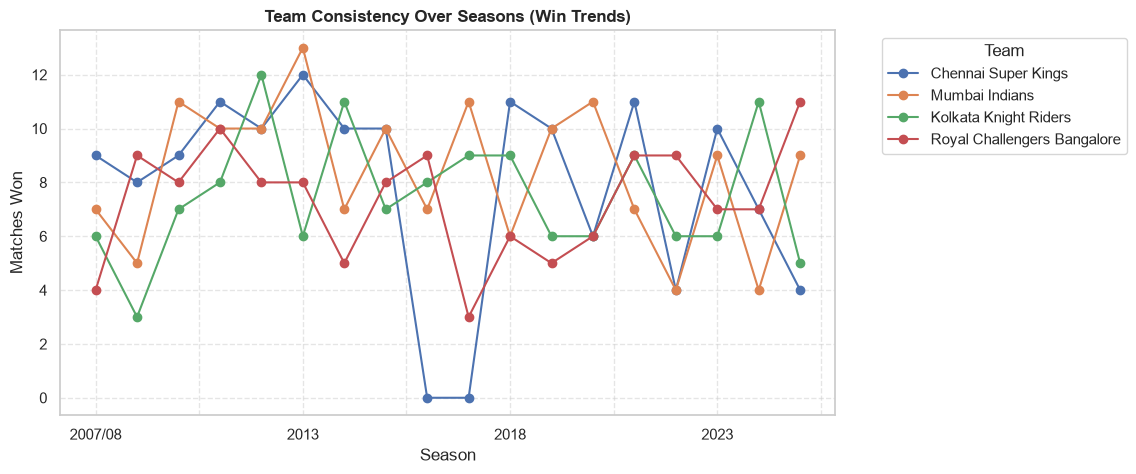

In [120]:
# Win count per team per season
team_season_wins = matches_df.drop_duplicates('match_id').groupby(['season', 'match_won_by']).size().unstack(fill_value=0)

# Select top 5 prominent franchises
top_teams = ['Chennai Super Kings', 'Mumbai Indians', 'Kolkata Knight Riders', 'Royal Challengers Bangalore']
team_season_wins[top_teams].plot(kind='line', marker='o', figsize=(10, 5))

plt.title('Team Consistency Over Seasons (Win Trends)', fontweight='bold')
plt.xlabel('Season')
plt.ylabel('Matches Won')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Team', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

In [121]:
#14. VICTORY SEVERITY MARGINS

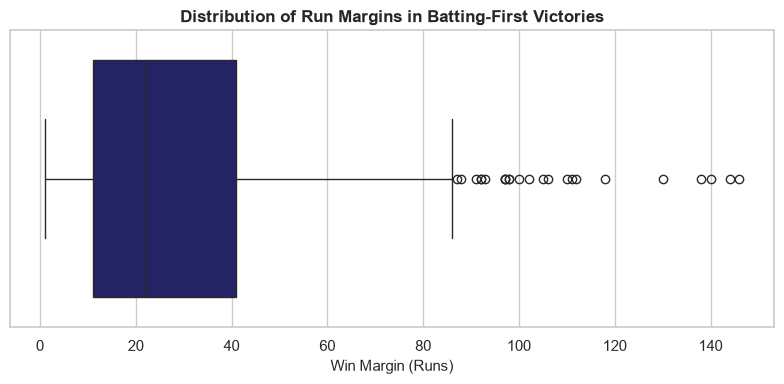

In [122]:
# Filter matches won by runs and extract the numeric margin
runs_wins = matches_df[matches_df['win_outcome'].astype(str).str.contains('runs', case=False, na=False)].drop_duplicates('match_id').copy()

# Extract numeric value from strings like '140 runs' -> 140
runs_wins['margin_runs'] = runs_wins['win_outcome'].str.extract(r'(\d+)').astype(float)

plt.figure(figsize=(8, 4))
sns.boxplot(
    data=runs_wins, 
    x='margin_runs', 
    color='#191970'
)

plt.title('Distribution of Run Margins in Batting-First Victories', fontweight='bold', fontsize=12)
plt.xlabel('Win Margin (Runs)', fontsize=11)
plt.tight_layout()
plt.show()